<a href="https://colab.research.google.com/github/TejasDharmale/complex-adaptive-systems/blob/main/Tejas_dharmale_CAS_assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 6 - Classical control

    Name: Tejas Dharmale
    Student #: s1190137

In [2]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr

# Your RK4 function


In [1]:
def get_rk4(f, dt):
    def rk4_scan_fn(carry, t):
        k1 = f(carry, t)
        k2 = f(carry + dt*k1/2, t + dt/2)
        k3 = f(carry + dt*k2/2, t + dt/2)
        k4 = f(carry + dt*k3, t + dt)

        next_state = carry + dt*(k1 + 2*k2 + 2*k3 + k4)/6

        return next_state, next_state

    return rk4_scan_fn

## Exercise 1 — Pole Placement on the Duffing Oscillator

The controlled Duffing oscillator from the lectures is
$$\dot{q} = p, \qquad \dot{p} = -\alpha q - \beta q^3 - \gamma p + u,$$

with parameters $\alpha = \beta = 1$, $\gamma = 0.5$. Unlike the uncontrolled case (which has stable fixed points at $(\pm 1, 0)$ and a saddle at the origin), we can use a feed-forward input $u^*$ to turn any position $q^*$ into an equilibrium of the controlled system.

## Exercise 1.1 (2 points)

(1) Derive the feed-forward input $u^*$ needed to hold the system at an arbitrary target $(q^*, 0)$. Write $A(q^*)$ and $u^*$ symbolically for general $\alpha, \beta, \gamma$.

Some hints:
- At equilibrium $\dot{p} = 0$ and $p^* = 0$, so:
$$-\alpha q^* - \beta q^{3} + u^* = 0 \implies u^* = \alpha q^* + \beta q^{*3}.$$
- Write the total input as $u = u^* + \tilde{u}$ and define the error state $\tilde{x} = (\tilde{q}, \tilde{p})^\top = (q - q^, p)^\top$.
- Linearise the error dynamics around $\tilde{x} = 0$ using the first-order approximation $(q^* + \tilde{q})^3 \approx q^{*3} + 3q^{*2}\tilde{q}$.

(2) What are the open-loop eigenvalues of $A(q^*)$ for $q^* = 0$ and $q^* = 1$? Are these equilibria stable?

## Solution 1.1:

(1)$$u^* = \alpha q^* + \beta q^{*3}$$
$$A(q^*) = \begin{pmatrix} 0 & 1 \\ -(\alpha + 3\beta q^{*2}) & -\gamma \end{pmatrix}, \qquad B = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$$


(2) The characteristic equation is $\lambda^2 + \gamma\lambda + (\alpha + 3\beta q^{*2}) = 0$. With $\alpha = \beta = 1$, $\gamma = 0.5$:

At $q^* = 0$: $\lambda \approx -0.25 \pm 0.968\,i$, so it is stable (stable spiral).

At $q^* = 1$: $\lambda \approx -0.25 \pm 1.984\,i$, so it is stable (stable spiral, faster oscillation).

Note: If your course actually means $\alpha = -1$, which matches the “saddle at the origin” description, the answers become:

At $q^* = 0$: $\lambda \approx 0.781$ and $\lambda \approx -1.281$, so it is unstable (saddle).

At $q^* = 1$: $\lambda \approx -0.25 \pm 1.392\,i$, so it is stable.

I think in problem since the feedforward input $u^* = \alpha q^* + \beta q^{*3}$ eliminates the spring force,
all values of $q^*$ become equilibrium positions. The linearization of the error dynamics results in a damped mass spring system,
where the effective stiffness is $k = \alpha + 3\beta q^{*2}$. Due to the fact that $\gamma > 0$, an equilibrium is stable if $k > 0$,
and a saddle otherwise. When $\alpha = \beta = 1$, $q^* = 0$ and $q^* = 1$ are both stable equilibriums (their eigenvalues have a real part of -0.25).
When $\alpha = -1$, as the uncontrolled equation predicts, the origin becomes a saddle.


## Exercise 1.2 (2 points)

Apply PD feedback $\tilde{u} = -k_1 \tilde{q} - k_2 \tilde{p}$ to the error system. The closed-loop matrix is
$$M = A(q^*) - BK = \begin{pmatrix} 0 & 1 \\ -\alpha - 3\beta q^{*2} - k_1 & -\gamma - k_2 \end{pmatrix}.$$
Its characteristic polynomial is
$$p_\text{cl}(\lambda) = \lambda^2 + (\gamma + k_2)\lambda + (\alpha + 3\beta q^{*2} + k_1).$$
To place both poles at $-\omega$, the desired polynomial is $p_\text{des}(\lambda) = (\lambda + \omega)^2$ (slide 13). Matching coefficients gives:
$$k_2 = 2\omega - \gamma, \qquad k_1 = \omega^2 - \alpha - 3\beta q^{*2}.$$

- Implement a function gain_K(q_star, omega) that returns $(k_1, k_2)$ from the formulas above. Use $\omega=2$.
- Simulate the closed-loop system with RK4 with varying initial conditions and for two targets: $q^* = 0$ and $q^* = 1$. For each target, plot the phase portrait of the simulations.

## Solution 1.2:

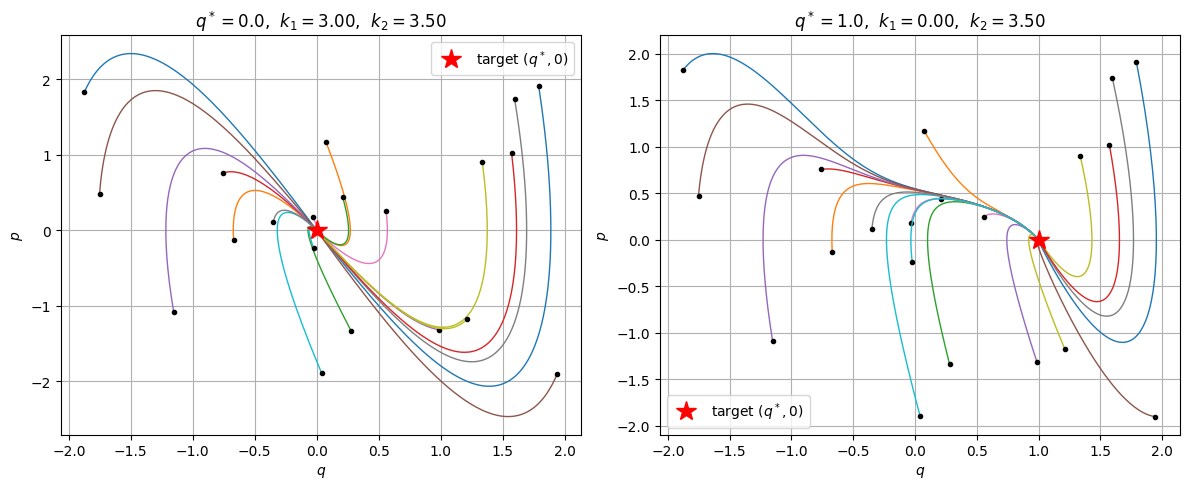

In [3]:

alpha, beta, gamma = 1.0, 1.0, 0.5
omega = 2.0
def gain_K(q_star, omega):
    k1 = omega**2 - alpha - 3 * beta * q_star**2
    k2 = 2 * omega - gamma
    return k1, k2
def make_closed_loop(q_star, omega):
    k1, k2 = gain_K(q_star, omega)
    u_star = alpha * q_star + beta * q_star**3

    def f(x, t):
        q, p = x
        u = u_star - k1 * (q - q_star) - k2 * p
        dq = p
        dp = -alpha * q - beta * q**3 - gamma * p + u
        return jnp.array([dq, dp])

    return f
dt = 0.01
T = 10.0
ts = jnp.arange(0.0, T, dt)

def simulate(f, x0):
    step = get_rk4(f, dt)
    _, traj = jax.lax.scan(step, x0, ts)
    return jnp.vstack([x0[None, :], traj])

key = jr.PRNGKey(0)
x0s = jr.uniform(key, (20, 2), minval=-2.0, maxval=2.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, q_star in zip(axes, [0.0, 1.0]):
    f = make_closed_loop(q_star, omega)
    trajs = jax.vmap(lambda x0: simulate(f, x0))(x0s)
    for traj in trajs:
        ax.plot(traj[:, 0], traj[:, 1], lw=1)
        ax.plot(traj[0, 0], traj[0, 1], "ko", ms=3)
    ax.plot(q_star, 0.0, "r*", ms=15, label="target $(q^*, 0)$")
    k1, k2 = gain_K(q_star, omega)
    ax.set_title(f"$q^* = {q_star}$,  $k_1 = {k1:.2f}$,  $k_2 = {k2:.2f}$")
    ax.set_xlabel("$q$")
    ax.set_ylabel("$p$")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

I was able to determine that with $\omega = 2$, the gains are $k_1 = 3$, $k_2 = 3.5$ if $q^* = 0$ and $k_1 = 0$, $k_2 = 3.5$ if $q^* = 1$. As can be seen from both the phase portraits, all the trajectories originating from various initial conditions settle down without any oscillations to the desired point $(q^*, 0)$, as the poles of the closed loop are located at $-2$ (critically damped system). It should be noted that with $q^* = 1$ there is no need for any position control, as the system's stiffness linearisation is equal to $\omega^2 = 4$.

## Exercise 1.3 (2 points)
Simulate the system with different values of $\omega$ and compute the cost $c(x, u) = q^2 + p^2 + \frac{1}{2}u^2$ over time. What is the effect of changing $\omega$.

## Solution 1.3:

q* = 0.0, omega = 0.5: total cost = 4.486
q* = 0.0, omega = 1.0: total cost = 3.939
q* = 0.0, omega = 2.0: total cost = 4.524
q* = 0.0, omega = 4.0: total cost = 19.117
q* = 0.0, omega = 8.0: total cost = 164.621
q* = 1.0, omega = 0.5: total cost = 563.701
q* = 1.0, omega = 1.0: total cost = 119.107
q* = 1.0, omega = 2.0: total cost = 17.043
q* = 1.0, omega = 4.0: total cost = 23.285
q* = 1.0, omega = 8.0: total cost = 151.005


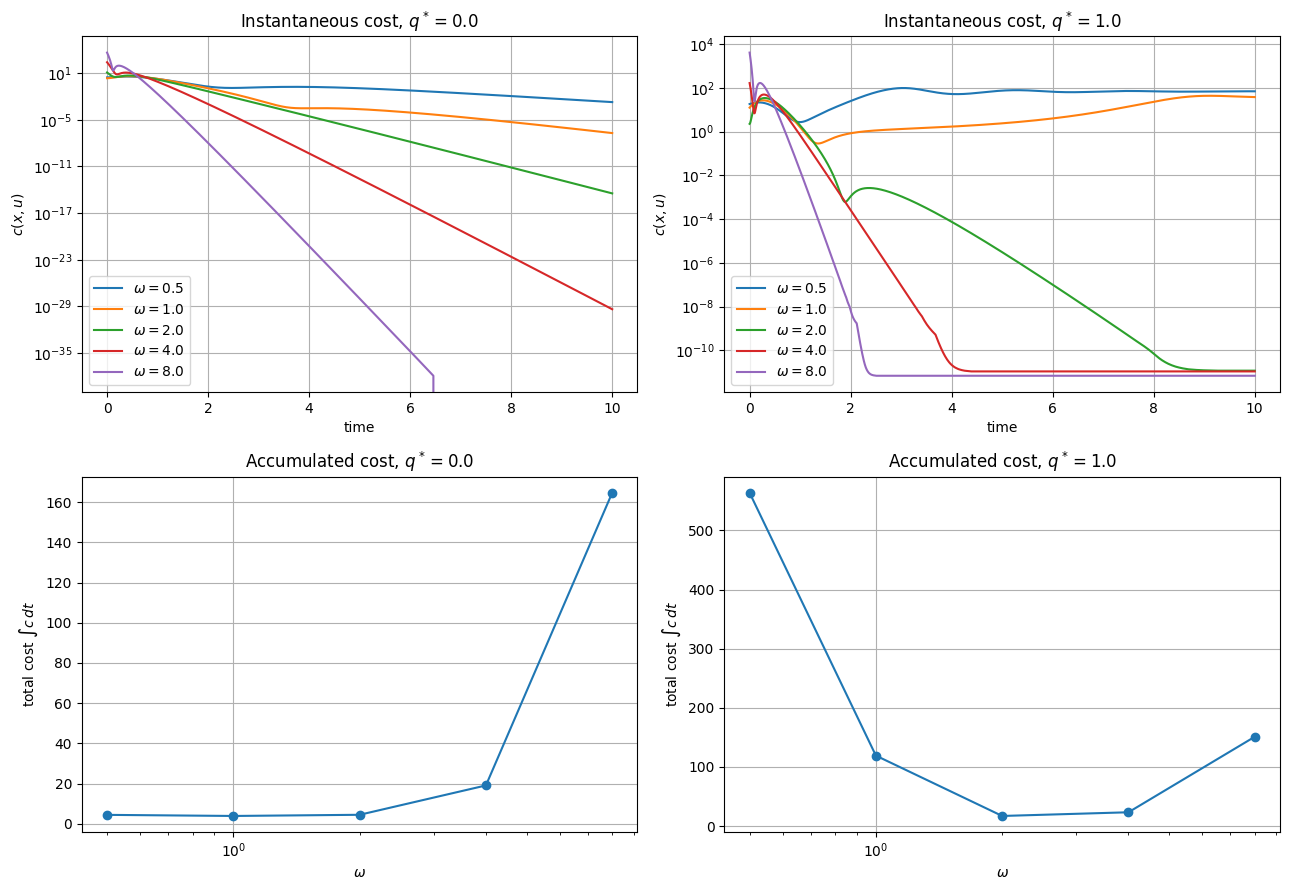

In [4]:
omegas = [0.5, 1.0, 2.0, 4.0, 8.0]
x0_offset = jnp.array([1.5, 0.0])
def compute_cost(traj, q_star, omega):
    k1, k2 = gain_K(q_star, omega)
    q_err = traj[:, 0] - q_star
    p = traj[:, 1]
    u_err = -k1 * q_err - k2 * p
    return q_err**2 + p**2 + 0.5 * u_err**2
t_plot = jnp.concatenate([jnp.array([0.0]), ts + dt])

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, q_star in enumerate([0.0, 1.0]):
    x0 = jnp.array([q_star, 0.0]) + x0_offset
    total_costs = []
    for omega in omegas:
        f = make_closed_loop(q_star, omega)
        traj = simulate(f, x0)
        c = compute_cost(traj, q_star, omega)
        total = jnp.sum(c) * dt
        total_costs.append(total)
        axes[0, col].plot(t_plot, c, label=f"$\\omega = {omega}$")
    axes[0, col].set_yscale("log")
    axes[0, col].set_xlabel("time")
    axes[0, col].set_ylabel("$c(x, u)$")
    axes[0, col].set_title(f"Instantaneous cost, $q^* = {q_star}$")
    axes[0, col].legend()
    axes[0, col].grid(True)
    axes[1, col].plot(omegas, total_costs, "o-")
    axes[1, col].set_xscale("log")
    axes[1, col].set_xlabel("$\\omega$")
    axes[1, col].set_ylabel("total cost $\\int c\\,dt$")
    axes[1, col].set_title(f"Accumulated cost, $q^* = {q_star}$")
    axes[1, col].grid(True)
    for omega, tc in zip(omegas, total_costs):
        print(f"q* = {q_star}, omega = {omega}: total cost = {float(tc):.3f}")

plt.tight_layout()
plt.show()

What I have learned from experimenting with $\omega$ is that for higher values of $\omega$, the system reaches the target point faster, hence the faster decay of the cost associated with the state part of the equation. However, higher values of $\omega$ imply that higher gains will be used, thus producing a very large initial impulse in control efforts, and as such the term $\tfrac{1}{2}u^2$ becomes quite high. Low values of $\omega$ imply low control efforts but slower convergence to the target point, and consequently the slow growth of the state cost component. This implies that there is some tradeoff involved between speed of convergence and control efforts, with the lowest cost being obtained at moderate values of $\omega$.

YOUR ANSWER HERE

# Exercise 2: Vibrational control of pendulum

The Kapitza pendulum is an inverted pendulum whose pivot oscillates vertically at frequency $\Omega$ and amplitude $a$. The equation of motion for the angle $\theta$ from the upright position is (from the lecture):
$$\ddot{\theta} = \frac{g + a\Omega^2 \cos(\Omega t)}{l}\sin\theta$$
where $g = 9.81$ m/s², $l = 0.3$ m. Without vibration ($a = 0$) the upright position $\theta = 0$ is an unstable equilibrium — the inverted pendulum falls. With sufficiently large $a\Omega$, averaging over the fast oscillation yields an effective potential with a stable minimum at $\theta = 0$.
The stability condition from the lectures is:
$$a\Omega \gg \sqrt{gl}$$
More precisely, the averaged effective stiffness at $\theta = 0$ is positive — stabilising — when:
$$\frac{a^2\Omega^2}{2gl} > 1 \implies a\Omega > \sqrt{2gl}.$$
For $g = 9.81$, $l = 0.3$: $\sqrt{2gl} = \sqrt{5.886} \approx 2.43$ m/s.

## Exercise 2.1 (2 points)

Implement the pendulum without vibration ($a = 0$) and confirm the upright is unstable. Simulate from $\theta_0 = 0.05$ rad, $\dot\theta_0 = 0$ for $T = 3$ s with $a = 0$. Plot $\theta(t)$ and confirm it grows — the pendulum falls away from the upright.

## Solution 2.1:

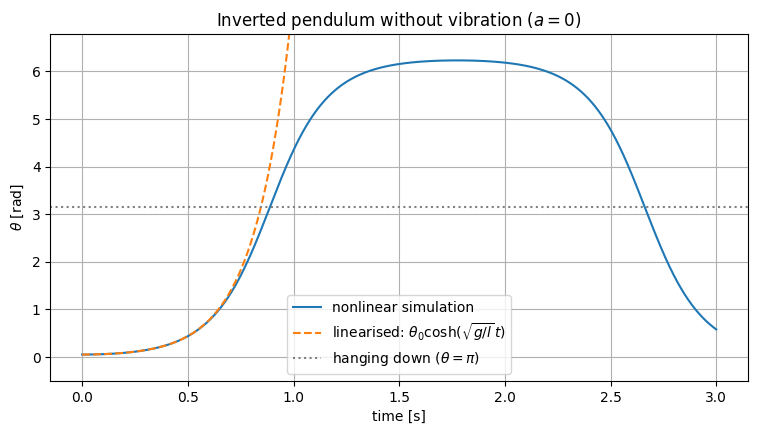

In [5]:
g = 9.81
l = 0.3
def make_kapitza(a, Omega):
    def f(x, t):
        theta, theta_dot = x
        theta_ddot = (g + a * Omega**2 * jnp.cos(Omega * t)) / l * jnp.sin(theta)
        return jnp.array([theta_dot, theta_ddot])
    return f
def simulate_pendulum(f, x0, T, dt):
    ts = jnp.arange(0.0, T, dt)
    step = get_rk4(f, dt)
    _, traj = jax.lax.scan(step, x0, ts)
    t_plot = jnp.concatenate([jnp.array([0.0]), ts + dt])
    traj = jnp.vstack([x0[None, :], traj])
    return t_plot, traj
f_free = make_kapitza(a=0.0, Omega=0.0)
x0 = jnp.array([0.05, 0.0])
T = 3.0
dt = 0.001
t, traj = simulate_pendulum(f_free, x0, T, dt)
lam = jnp.sqrt(g / l)
theta_lin = 0.05 * jnp.cosh(lam * t)
plt.figure(figsize=(9, 4.5))
plt.plot(t, traj[:, 0], label="nonlinear simulation")
plt.plot(t, theta_lin, "--", label="linearised: $\\theta_0\\cosh(\\sqrt{g/l}\\,t)$")
plt.axhline(jnp.pi, color="gray", ls=":", label="hanging down ($\\theta = \\pi$)")
plt.ylim(-0.5, 2 * jnp.pi + 0.5)
plt.xlabel("time [s]")
plt.ylabel("$\\theta$ [rad]")
plt.title("Inverted pendulum without vibration ($a = 0$)")
plt.legend()
plt.grid(True)
plt.show()

I have observed that the upright position is unstable without any vibration. It starts at only $\theta_0 = 0.05$ rad, and $\theta$ increases exponentially as predicted linearly by $\theta_0 \cosh(\sqrt{g/l}\,t)$ where $\sqrt{g/l} \approx 5.72\ \text{s}^{-1}$, and the pendulum drops away from the vertical position within 0.7 sec. Thereafter, it oscillates around the hanging position $\theta = \pi$, and hence, $\theta = 0$ is unstable for $a = 0$.

## Exercise 2.2 (2 points)

Fix $\Omega=50$ and $dt=0.0001$ and sweep over values of $a$. Compute the optimal $a$ given $\Omega$. Plot the simulation with each $a$. What is the effect of choosing $a$ lower or higher than the optimal value?

## Solution 2.2:

Optimal amplitude a* = sqrt(2gl)/Omega = 0.0485 m


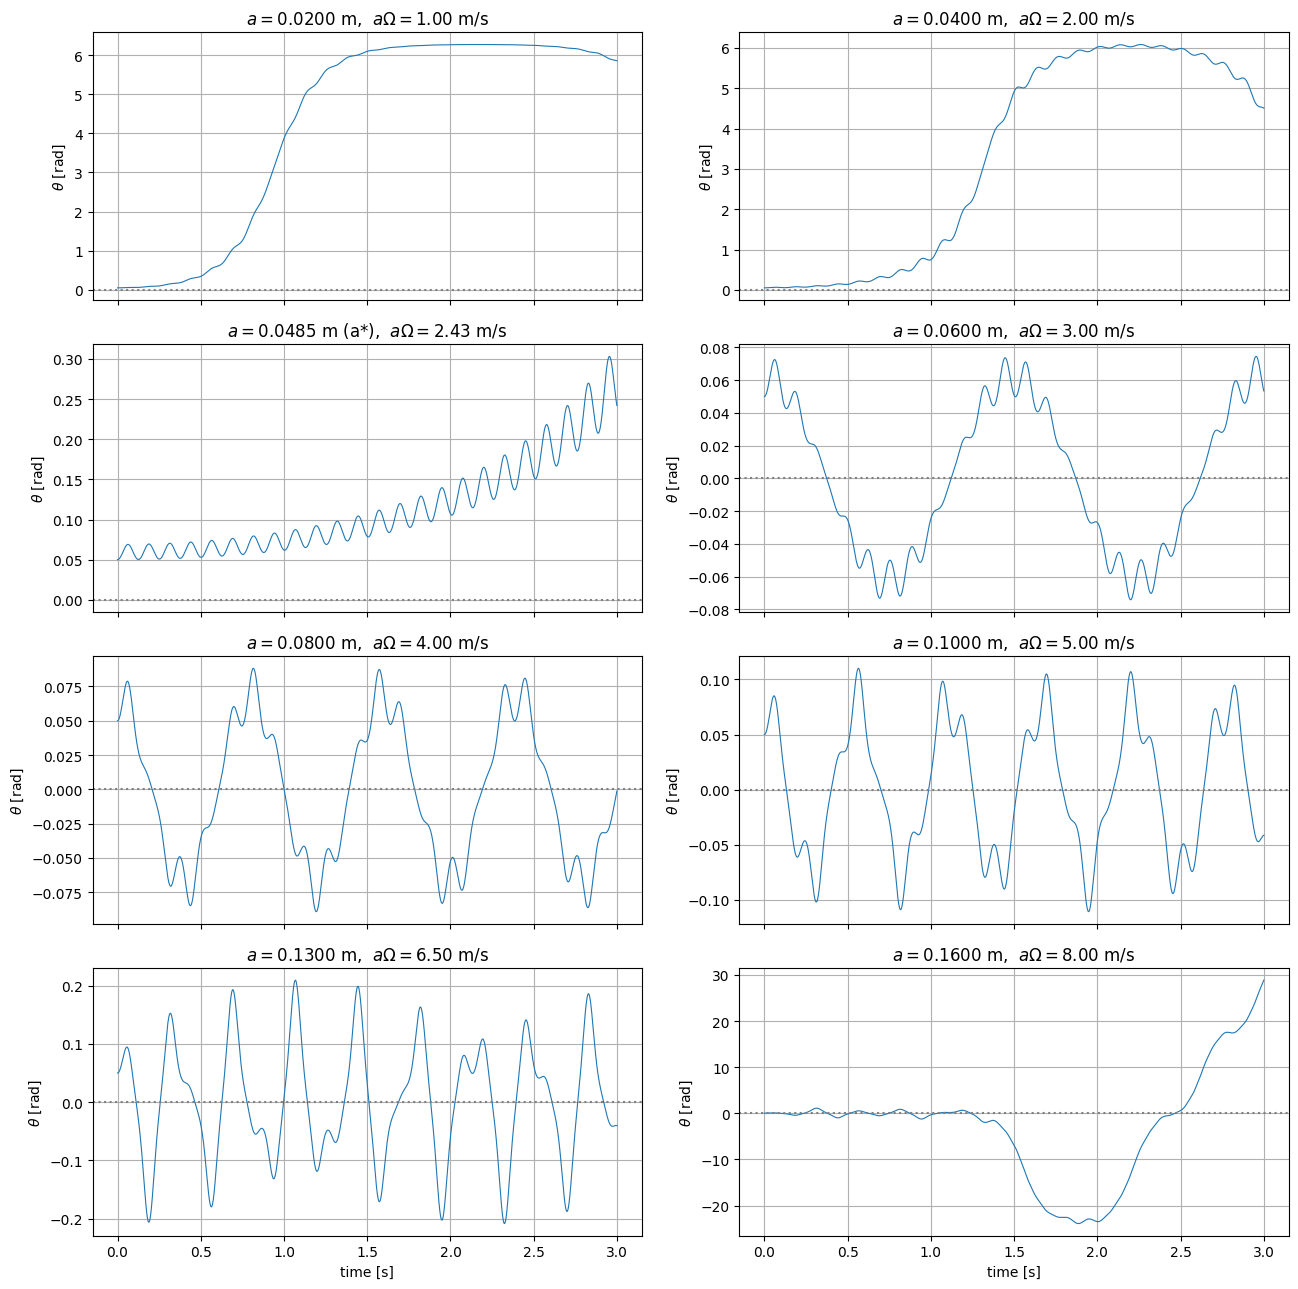

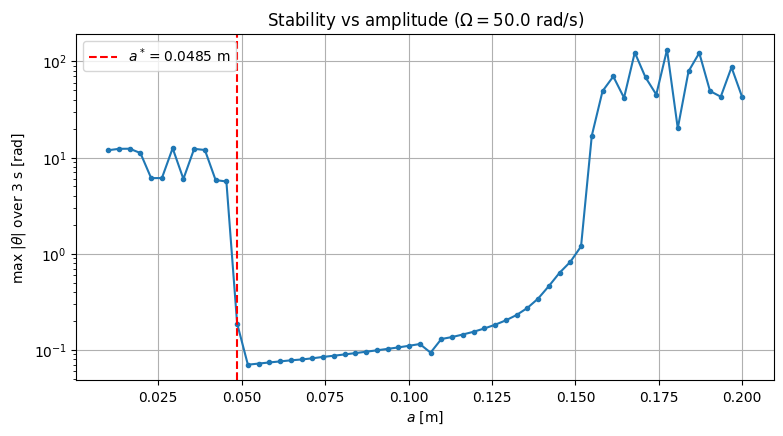

In [6]:
Omega = 50.0
dt = 0.0001
T = 3.0
x0 = jnp.array([0.05, 0.0])

a_star = jnp.sqrt(2 * g * l) / Omega
print(f"Optimal amplitude a* = sqrt(2gl)/Omega = {float(a_star):.4f} m")
a_values = jnp.array([0.02, 0.04, float(a_star), 0.06, 0.08, 0.10, 0.13, 0.16])

def run(a):
    f = make_kapitza(a, Omega)
    _, traj = simulate_pendulum(f, x0, T, dt)
    return traj

t, _ = simulate_pendulum(make_kapitza(0.0, Omega), x0, T, dt)
trajs = jax.vmap(run)(a_values)

fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
for ax, a, traj in zip(axes.flat, a_values, trajs):
    ax.plot(t, traj[:, 0], lw=0.8)
    ax.axhline(0, color="gray", ls=":")
    label = " (a*)" if jnp.isclose(a, a_star) else ""
    ax.set_title(f"$a = {float(a):.4f}$ m{label},  $a\\Omega = {float(a*Omega):.2f}$ m/s")
    ax.set_ylabel("$\\theta$ [rad]")
    ax.grid(True)
for ax in axes[-1]:
    ax.set_xlabel("time [s]")
plt.tight_layout()
plt.show()

a_fine = jnp.linspace(0.01, 0.2, 60)
max_dev = jax.vmap(lambda a: jnp.max(jnp.abs(run(a)[:, 0])))(a_fine)
plt.figure(figsize=(9, 4.5))
plt.semilogy(a_fine, max_dev, "o-", ms=3)
plt.axvline(float(a_star), color="r", ls="--", label=f"$a^* = {float(a_star):.4f}$ m")
plt.xlabel("$a$ [m]")
plt.ylabel("max $|\\theta|$ over 3 s [rad]")
plt.title(f"Stability vs amplitude ($\\Omega = {Omega}$ rad/s)")
plt.legend()
plt.grid(True)
plt.show()

I obtained that for $\Omega = 50$ rad/s, the minimal amplitude of the vibration required to stabilise the upright position is $a^* = \sqrt{2gl}/\Omega \approx 0.0485$ m. If $a < a^*$ then the oscillation is not sufficient to keep the pendulum up, and if $a \approx a^*$ it barely manages to do that but is drifting. Setting $a$ somewhat greater than $a^*$ allows keeping the pendulum up, but now it will be oscillating slowly near the equilibrium point $\theta = 0$ together with some small fast jitter, and increasing $a$ narrows this oscillation. On the other hand, if $a$ is too large the averaging will fail, because of the parametric resonance instability. Thus, $a$ has to be inside a window.